In [1]:
from abc import ABC, abstractmethod
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
class Layer(ABC):
    
    @abstractmethod
    def forward(self, input):
        ...
    
    @abstractmethod
    def backward(self, gradient):
        ...
    
    @abstractmethod
    def update(self, lr):
        ...


In [3]:
class Loss(ABC):
    
    @abstractmethod
    def forward(self, target, preficted):
        ...
    
    @abstractmethod
    def backward(self, target, predicted):
        ...


In [4]:
class MSE(Loss):
    
    @staticmethod
    def forward(target, predicted):
        return np.sum(np.square(predicted - target)) / (target.shape[0] * target.shape[1])
    
    @staticmethod
    def backward(target, predicted):
        return 2 * (predicted - target) / (target.shape[0] * target.shape[1])



In [5]:
#binary cross-entropy

In [6]:
class BCE(Loss):

    @staticmethod
    def forward(target, predicted):
        predicted = np.clip(predicted, 1e-7, 1 - 1e-7)
        return -1 * (
            target * np.log(predicted)
            + (1 - target) * np.log(1 - predicted)
        )

    @staticmethod
    def backward(target, predicted):
        predicted = np.clip(predicted, 1e-7, 1 - 1e-7)
        return (predicted - target) / (
            predicted * (1 - predicted)
        )
    

In [7]:
class Dense(Layer):
    
    def __init__(self, in_features, out_features):
        super().__init__()
        
        self.in_features = in_features
        self.out_features = out_features
        
        # He initialization
        # self.weights = np.random.randn(in_features, out_features) * np.sqrt(2 / in_features)
        #Xavier
        self.weights = np.random.randn(in_features, out_features) * np.sqrt(2/ (in_features + out_features))
        self.biases = np.zeros(out_features)
    
    def forward(self, input):
        self.input = input
        return input @ self.weights + self.biases
    
    def backward(self, dZ):
        self.dweights = self.input.T @ dZ
        self.dbiases = np.sum(dZ, axis=0)
        return dZ @ self.weights.T
    
    def update(self, lr):
        self.weights -= lr * self.dweights
        self.biases -= lr * self.dbiases


In [8]:
class Sigmoid(Layer):
    
    def forward(self, input):
        self.value = 1 / (1 + np.exp(-1 * input))
        return self.value
    
    def backward(self, dA):
        return dA * (self.value * (1 - self.value))
    
    def update(self, lr):
        pass

In [9]:
class Softmax(Layer):

    def forward(self, input):
        exp_values = np.exp(input - np.max(input, axis=1, keepdims=True))
        self.mask = exp_values / np.sum(exp_values, axis=1, keepdims=True)
        return self.mask

    def backward(self, dA):
        return self.mask * (dA - np.sum(dA * self.mask, axis=1, keepdims=True))

    def update(self, lr):
        pass

In [10]:
class CCE:

    @staticmethod
    def forward(target, pred):
        pred = np.clip(pred, 1e-12, 1.0)
        return -np.sum(target * np.log(pred)) / target.shape[0]

    @staticmethod
    def backward(target, pred):
        pred = np.clip(pred, 1e-12, 1.0)
        return -target / pred / target.shape[0]

In [11]:
class ReLU(Layer):
    
    def forward(self, input):
        self.mask = input > 0
        return np.maximum(0, input)
    
    def backward(self, dA):
        return dA * self.mask
    
    def update(self, lr):
        pass

In [12]:
class LeakyReLU(Layer):
    
    def forward(self, input):
        self.mask = input > 0
        return np.where(self.mask, input, input * 0.1)
    
    def backward(self, dA):
        dx = np.where(self.mask, 1.0, 0.1)
        return dA * dx
    
    def update(self, lr):
        pass

In [13]:
class Network():
    
    def __init__(self, layers):
        self.layers = layers
    
    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X

    def backward(self, gradient):
        for layer in reversed(self.layers):
            gradient = layer.backward(gradient)

    def update(self, lr):
        for layer in self.layers:
            layer.update(lr)



In [14]:


# per = Network(
#     [
#         Dense(2, 512),
#         ReLU(),
#         Dense(512, 256),
#         ReLU(),
#         Dense(256, 128),
#         ReLU(),
#         Dense(128, 64),
#         ReLU(),
#         Dense(64, 3),
#         Softmax(),
#     ]
# )

per = Network(
    [
        Dense(2, 32),
        LeakyReLU(),
        Dense(32, 16),
        LeakyReLU(),
        Dense(16, 3),
        Softmax(),
    ]
)


In [15]:
#learning

In [16]:
df = pd.read_csv("data.three_gauss.train.10000.csv")

n = 50
epochs = 1000
learning_rate = 0.001

list_df = [df[i:i + n] for i in range(0, df.shape[0], n)]

for epoch in range(epochs):
    epoch_loss = 0

    for batch in list_df:
        labels = batch.iloc[:, -1].to_numpy().astype(int) - 1
        target = np.eye(3)[labels]

        inputs = batch.iloc[:, :2].to_numpy()

        pred = per.forward(inputs)

        loss = CCE.forward(target, pred)
        gradient = CCE.backward(target, pred)

        per.backward(gradient)
        per.update(learning_rate)

        epoch_loss += loss * len(batch)

    epoch_loss /= len(df)

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1}, Loss: {epoch_loss:.4f}")

   # print(f"Epoch {epoch + 1}, Loss: {epoch_loss:.4f}")



Epoch 50, Loss: 0.2018
Epoch 100, Loss: 0.1833
Epoch 150, Loss: 0.1759
Epoch 200, Loss: 0.1717
Epoch 250, Loss: 0.1689
Epoch 300, Loss: 0.1665
Epoch 350, Loss: 0.1646
Epoch 400, Loss: 0.1628
Epoch 450, Loss: 0.1612
Epoch 500, Loss: 0.1599
Epoch 550, Loss: 0.1587
Epoch 600, Loss: 0.1577
Epoch 650, Loss: 0.1568
Epoch 700, Loss: 0.1560
Epoch 750, Loss: 0.1553
Epoch 800, Loss: 0.1546
Epoch 850, Loss: 0.1539
Epoch 900, Loss: 0.1533
Epoch 950, Loss: 0.1527
Epoch 1000, Loss: 0.1521


Loss: 0.18202073179429445
Predictions (probabilities):
[[9.98436352e-01 5.07300831e-06 1.55857495e-03]
 [9.91298373e-01 3.01922409e-04 8.39970410e-03]
 [1.77640227e-01 2.63624436e-01 5.58735337e-01]
 [9.23004598e-01 5.63354941e-03 7.13618531e-02]
 [9.98265981e-01 4.53481224e-06 1.72948375e-03]
 [9.93041144e-01 1.89328633e-04 6.76952697e-03]
 [9.85189598e-01 9.24367585e-05 1.47179649e-02]
 [7.21807985e-01 3.99758670e-03 2.74194429e-01]
 [3.99901874e-01 8.49108002e-02 5.15187326e-01]
 [6.02794516e-01 7.98362406e-03 3.89221860e-01]
 [9.96547797e-01 1.64906237e-04 3.28729684e-03]
 [9.74489318e-01 1.63076898e-04 2.53476049e-02]
 [9.98357870e-01 2.27520578e-05 1.61937783e-03]
 [9.96872629e-01 3.18231969e-04 2.80913863e-03]
 [9.96962356e-01 7.13284564e-06 3.03051068e-03]
 [9.83880762e-01 1.08839608e-04 1.60103981e-02]
 [9.12351216e-02 3.19503859e-03 9.05569840e-01]
 [9.04670221e-01 6.61119627e-03 8.87185823e-02]
 [9.38562317e-01 1.67231992e-03 5.97653632e-02]
 [8.37576361e-01 3.21203800e-03 1

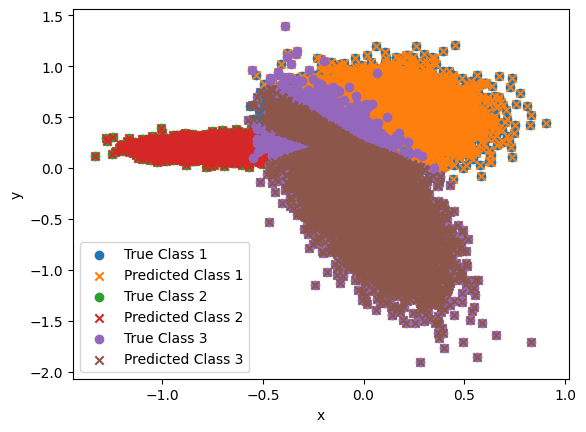

Weights:
[[-6.11761817e-01  1.16534122e-01 -7.58635094e-01 -3.96201870e-02
  -1.44880954e-01  1.76295872e-01 -9.36376231e-03  2.51975888e-01
   3.85299615e-01 -8.13454045e-02  8.88631987e-03 -2.58861063e-01
   4.90459192e-01  3.75031818e-01  2.73237009e-02 -2.37342956e-02
   2.12359605e-02 -1.15843118e-01 -6.81967199e-01  4.13540168e-01
  -1.42583142e-01  2.38926357e-01  1.69041106e-01 -5.75420626e-01
  -2.58423411e-02 -8.53374126e-01 -3.73666528e-01 -3.81031492e-01
   2.22647428e-01 -1.26910895e+00  2.34682941e-01  1.06487273e-01]
 [-9.85598048e-02 -8.03081911e-01 -5.97842270e-01 -4.86248090e-02
   1.59152715e-01  9.47366327e-02 -1.27140314e-01 -2.72462133e-04
  -8.93963521e-02 -1.13519501e-01 -1.40848913e-01  1.66761219e-01
   6.21674199e-01  1.28006718e+00 -1.82770904e-01 -9.44788215e-02
  -3.10097800e-01  1.33598995e+00 -4.05363062e-01 -1.83511038e+00
   9.85691551e-01  5.98204926e-01 -5.38931922e-02 -8.68535076e-01
  -4.09495173e-01 -4.09570850e-01  1.90186795e-01 -1.67657060e-01


In [17]:
df = pd.read_csv("data.three_gauss.test.10000.csv")

inputs = df.iloc[:, :2].to_numpy()
target = df.iloc[:, -1:].to_numpy().astype(int)

target_one_hot = np.eye(3)[target[:, 0] - 1]

pred = per.forward(inputs)

loss = CCE.forward(target_one_hot, pred)

pred_class = np.argmax(pred, axis=1).reshape(-1, 1) + 1

print("Loss:", loss)
print("Predictions (probabilities):")
print(pred[:20])
print("Predicted classes:")
print(pred_class[:20])
print("Real classes:")
print(target[:20])

accuracy = np.mean(pred_class == target)
print("Accuracy:", accuracy)

x = df.iloc[:, 0].to_numpy()
y = df.iloc[:, 1].to_numpy()

for cls in [1, 2, 3]:
    plt.scatter(
        x[target[:, 0] == cls],
        y[target[:, 0] == cls],
        label=f"True Class {cls}"
    )

    plt.scatter(
        x[pred_class[:, 0] == cls],
        y[pred_class[:, 0] == cls],
        marker="x",
        label=f"Predicted Class {cls}"
    )

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

print("Weights:")
print(per.layers[0].weights)

print("Biases:")
print(per.layers[0].biases)


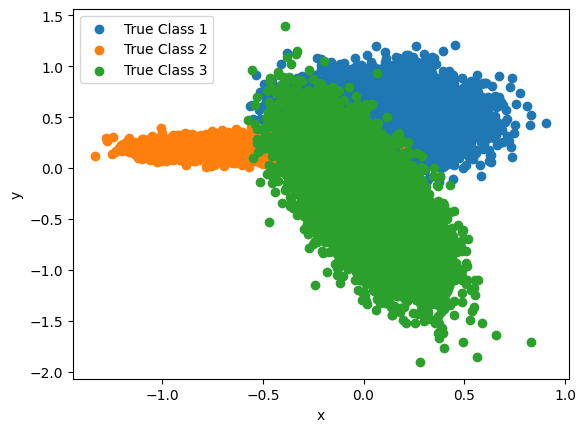

In [18]:
target = df.iloc[:, -1:].to_numpy().astype(int)

for cls in [1, 2, 3]:
    plt.scatter(
        x[target[:, 0] == cls],
        y[target[:, 0] == cls],
        label=f"True Class {cls}"
    )

# plt.xlim(-2, 1)
# plt.ylim(-2, 1.5)

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

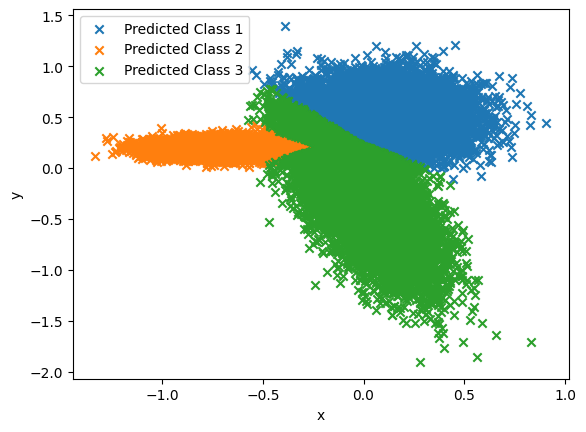

In [19]:
for cls in [1, 2, 3]:

    plt.scatter(
        x[pred_class[:, 0] == cls],
        y[pred_class[:, 0] == cls],
        marker="x",
        label=f"Predicted Class {cls}"
    )

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [20]:
#class 1

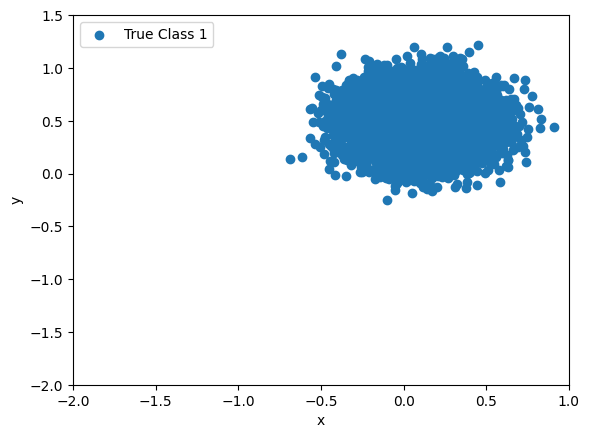

In [21]:
    plt.scatter(
        x[target[:, 0] == 1],
        y[target[:, 0] == 1],
        label=f"True Class {1}"
    )

plt.xlim(-2, 1)
plt.ylim(-2, 1.5)

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [22]:
#class 2

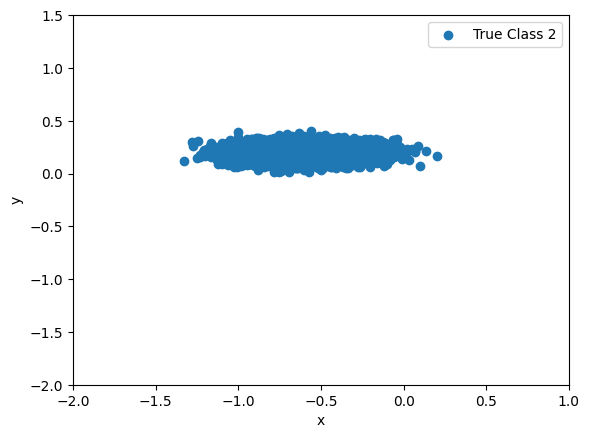

In [23]:
    plt.scatter(
        x[target[:, 0] == 2],
        y[target[:, 0] == 2],
        label=f"True Class {2}"
    )

plt.xlim(-2, 1)
plt.ylim(-2, 1.5)

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

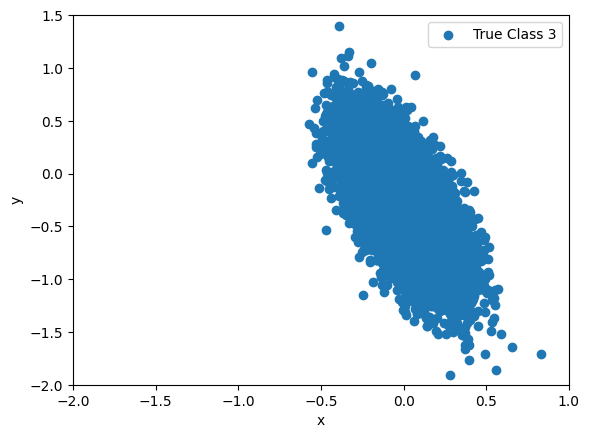

In [24]:
    plt.scatter(
        x[target[:, 0] == 3],
        y[target[:, 0] == 3],
        label=f"True Class {3}"
    )
plt.xlim(-2, 1)
plt.ylim(-2, 1.5)
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [25]:
#basic

In [26]:


# per = Network(
#     [
#         Dense(2, 512),
#         ReLU(),
#         Dense(512, 256),
#         ReLU(),
#         Dense(256, 128),
#         ReLU(),
#         Dense(128, 64),
#         ReLU(),
#         Dense(64, 3),
#         Softmax(),
#     ]
# )

per2 = Network(
    [
        Dense(2, 32),
        LeakyReLU(),
        Dense(32, 16),
        LeakyReLU(),
        Dense(16, 2),
        Softmax(),
    ]
)

In [30]:
df = pd.read_csv("data.simple.train.1000.csv")

# Zostawiamy tylko klasy 1 i 2
df = df[df.iloc[:, -1].isin([1, 2])].copy()

n = 50
epochs = 5000
learning_rate = 0.001



list_df = [df.iloc[i:i + n] for i in range(0, df.shape[0], n)]

for epoch in range(epochs):
    epoch_loss = 0

    for batch in list_df:
        labels = batch.iloc[:, -1].to_numpy().astype(int) - 1
        target_one_hot = np.eye(2)[labels]

        inputs = batch.iloc[:, :2].to_numpy()

        pred = per2.forward(inputs)

        loss = CCE.forward(target_one_hot, pred)
        gradient = CCE.backward(target_one_hot, pred)

        per2.backward(gradient)
        per2.update(learning_rate)

        epoch_loss += loss * len(batch)

    epoch_loss /= len(df)

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1}, Loss: {epoch_loss:.4f}")

Epoch 50, Loss: 0.0644
Epoch 100, Loss: 0.0624
Epoch 150, Loss: 0.0605
Epoch 200, Loss: 0.0587
Epoch 250, Loss: 0.0571
Epoch 300, Loss: 0.0556
Epoch 350, Loss: 0.0542
Epoch 400, Loss: 0.0529
Epoch 450, Loss: 0.0517
Epoch 500, Loss: 0.0505
Epoch 550, Loss: 0.0494
Epoch 600, Loss: 0.0483
Epoch 650, Loss: 0.0473
Epoch 700, Loss: 0.0464
Epoch 750, Loss: 0.0455
Epoch 800, Loss: 0.0447
Epoch 850, Loss: 0.0439
Epoch 900, Loss: 0.0431
Epoch 950, Loss: 0.0424
Epoch 1000, Loss: 0.0417
Epoch 1050, Loss: 0.0410
Epoch 1100, Loss: 0.0404
Epoch 1150, Loss: 0.0398
Epoch 1200, Loss: 0.0392
Epoch 1250, Loss: 0.0387
Epoch 1300, Loss: 0.0381
Epoch 1350, Loss: 0.0376
Epoch 1400, Loss: 0.0371
Epoch 1450, Loss: 0.0366
Epoch 1500, Loss: 0.0362
Epoch 1550, Loss: 0.0357
Epoch 1600, Loss: 0.0353
Epoch 1650, Loss: 0.0348
Epoch 1700, Loss: 0.0344
Epoch 1750, Loss: 0.0340
Epoch 1800, Loss: 0.0337
Epoch 1850, Loss: 0.0333
Epoch 1900, Loss: 0.0329
Epoch 1950, Loss: 0.0326
Epoch 2000, Loss: 0.0322
Epoch 2050, Loss: 0.

Loss: 0.021283659466972957
Predictions (probabilities):
[[9.99999952e-01 4.81553391e-08]
 [2.56459794e-05 9.99974354e-01]
 [9.99999996e-01 4.09841839e-09]
 [2.33217562e-13 1.00000000e+00]
 [1.00000000e+00 1.61818177e-11]
 [6.83817032e-03 9.93161830e-01]
 [1.43534896e-04 9.99856465e-01]
 [9.99901682e-01 9.83179833e-05]
 [9.98949502e-01 1.05049754e-03]
 [9.99999392e-01 6.07531309e-07]
 [1.00000000e+00 1.02932345e-12]
 [9.99985325e-01 1.46752747e-05]
 [5.53870397e-10 9.99999999e-01]
 [9.99992548e-01 7.45177557e-06]
 [9.99999999e-01 9.04184923e-10]
 [9.99999914e-01 8.57734490e-08]
 [4.19027494e-06 9.99995810e-01]
 [9.19323350e-01 8.06766495e-02]
 [9.99999986e-01 1.35952102e-08]
 [9.99999469e-01 5.30869799e-07]]
Predicted classes:
[[1]
 [2]
 [1]
 [2]
 [1]
 [2]
 [2]
 [1]
 [1]
 [1]
 [1]
 [1]
 [2]
 [1]
 [1]
 [1]
 [2]
 [1]
 [1]
 [1]]
Real classes:
[[1]
 [2]
 [1]
 [2]
 [1]
 [2]
 [2]
 [1]
 [1]
 [1]
 [1]
 [1]
 [2]
 [1]
 [1]
 [1]
 [2]
 [1]
 [1]
 [1]]
Accuracy: 0.997


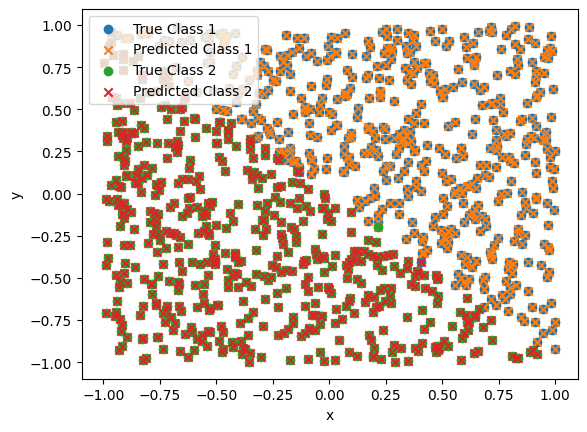

Weights:
[[ 0.77410229 -0.13859959  0.24668287 -0.72335769 -0.06012697 -0.68882164
  -0.2312667  -0.97787871 -0.23324805  0.49386716  0.02853579 -0.61292936
  -0.01816256  0.0344248  -0.10367116 -0.14257306 -0.1311008  -0.05772477
  -0.48175975 -0.27521173 -0.35493453 -0.52924037  0.3511184  -0.73539256
   0.92807755 -0.03395104  0.16151418 -0.11223172  0.26884316  0.93123683
   0.20591    -0.37600832]
 [ 0.61921859 -0.13772461  0.41240502 -0.16811528 -0.17851571 -0.1594945
  -0.46073049 -0.97068881  0.0573319   0.52274746  0.27196117 -0.67672299
   0.06970409 -0.22625809 -0.19769016 -0.0620682  -0.66654525  0.15234614
  -0.48901319 -0.3946678  -0.47015894  0.37989125 -0.01303865 -0.76213133
   1.01675207  0.05718643 -0.4708198  -0.60057558 -0.103359    0.45017647
   0.07996731 -0.24690968]]
Biases:
[ 0.30530526 -0.03803454  0.25871102  0.1941265  -0.07865119  0.21059621
  0.2250445   0.29668656 -0.10567591  0.21206134  0.02871107  0.18628129
 -0.09319807 -0.03463287  0.01918771 -0.113

In [31]:


df = pd.read_csv("data.simple.train.1000.csv")


inputs = df.iloc[:, :2].to_numpy()

mask = df.iloc[:, -1].isin([1, 2]).to_numpy()
inputs = inputs[mask]
target = df.iloc[mask, -1:].to_numpy().astype(int)

target_one_hot = np.eye(2)[target[:, 0] - 1]

pred = per2.forward(inputs)

loss = CCE.forward(target_one_hot, pred)

pred_class = np.argmax(pred, axis=1).reshape(-1, 1) + 1

print("Loss:", loss)
print("Predictions (probabilities):")
print(pred[:20])

print("Predicted classes:")
print(pred_class[:20])

print("Real classes:")
print(target[:20])

accuracy = np.mean(pred_class == target)
print("Accuracy:", accuracy)

# Wykres
x = inputs[:, 0]
y = inputs[:, 1]

for cls in [1, 2]:
    plt.scatter(
        x[target[:, 0] == cls],
        y[target[:, 0] == cls],
        label=f"True Class {cls}"
    )

    plt.scatter(
        x[pred_class[:, 0] == cls],
        y[pred_class[:, 0] == cls],
        marker="x",
        label=f"Predicted Class {cls}"
    )

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

print("Weights:")
print(per2.layers[0].weights)

print("Biases:")
print(per2.layers[0].biases)